# Joint neutron lattice and strain fields

## 1. Problem

The target contains **four spatial unknowns**: stress-free lattice spacing $d_0(x,y)$ and the three in-plane tensor strains $\epsilon_{xx},\epsilon_{xy},\epsilon_{yy}$. A material-dependent variation in $d_0$ can look like mechanical deformation, so a strain-only reconstruction assuming constant spacing answers a different, restricted inverse problem.

This review uses the original author's complete native cantilever example, with 1798 simulated neutron paths and a 40×40 grid. The data were generated by the author's unchanged acquisition code in the original verification run, not measured at a beamline. We preserve the reproduced original source heuristic and its constant-spacing GP comparison, then separately reproduce a **qualified Eq19-objective Newton method**. Numerical and derivative corrections are disclosed; no unchanged reproduction claim is made for the qualified solver.

In [1]:
from pathlib import Path
import sys,time,os,json,hashlib
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.visualization import field_metrics,sensitivity,figures
from evaluation.judge import evaluate
data=load_data()
print('Actual kernel:',sys.executable)
print('NumPy:',np.__version__)
print('Bound raw SHA256:',hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest())
print({k:(v.shape,str(v.dtype)) for k,v in data.items()})

Actual kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe
NumPy: 2.4.6
Bound raw SHA256: b7d256ece33de13c47eaf69c52661024c108c6fda936f70e5d3cc01b5b40af28
{'observations': ((1798,), 'float64'), 'entry': ((1798, 2), 'float64'), 'exit': ((1798, 2), 'float64'), 'direction': ((1798, 2), 'float64'), 'path_length': ((1798,), 'float64'), 'grid_x': ((40, 40), 'float64'), 'grid_y': ((40, 40), 'float64'), 'traction_points': ((100, 2), 'float64'), 'traction_normals': ((100, 2), 'float64')}


## 2. Data

All intersecting paths from 30 angles and 100 detector pixels per angle are retained. The sample support is 20 mm×10 mm. Two hundred scalar zero-traction components at 100 top/bottom boundary positions are known independently. Coordinates are in metres; lattice spacings are in ångströms; strain is dimensionless tensor strain. The actual Gaussian noise standard deviation is $4.056\times10^{-4}$ Å, equivalent to $10^{-4}$ relative strain at the independently known nominal spacing 4.056 Å.

Neither the load magnitude nor the spatial chemical-profile formula is available to a solver. All lattice values, including both ends and the bulk, remain unknown during inversion. Actual author simulation truth is used only for assessment. The original generic `polyxpoly` and `blockproc` APIs required explicitly documented oracle compatibility helpers, tested against independent geometry; the published mathematical files were unchanged in the first source run.

In [2]:
with np.load(ROOT/'evaluation/ground_truth.npz',allow_pickle=False) as z: truth={k:z[k].copy() for k in z.files}
with np.load(ROOT/'notebooks/reference_outputs/original_source.npz',allow_pickle=False) as z: original={k:z[k].copy() for k in z.files}
with np.load(ROOT/'notebooks/reference_outputs/qualified_source.npz',allow_pickle=False) as z: qualified={k:z[k].copy() for k in z.files}
print('Absolute spacing range (Å):',data['observations'].min(),data['observations'].max())
print('Native rays:',len(data['observations']),'known boundary points:',len(data['traction_points']))

Absolute spacing range (Å): 4.050778358976379 4.078993286745399
Native rays: 1798 known boundary points: 100


## 3. Physics

For entry point $p_i$, unit direction $n_i$ and path length $L_i$,

$$ y_i={1\over L_i}\int_0^{L_i}d_0(p_i+s n_i)\left[1+n_{ix}^2\epsilon_{xx}+2n_{ix}n_{iy}\epsilon_{xy}+n_{iy}^2\epsilon_{yy}\right]ds+\eta_i. $$

The strains in the integral are evaluated at the same point as $d_0$. This product is the key physical coupling. A normalized Airy potential $\phi$ gives

$$\epsilon_{xx}=\phi_{yy}-\nu\phi_{xx},\qquad \epsilon_{xy}=-(1+\nu)\phi_{xy},\qquad \epsilon_{yy}=\phi_{xx}-\nu\phi_{yy},\quad\nu=0.3.$$

Its stress components are $(\sigma_{xx},\sigma_{xy},\sigma_{yy})/E=(\phi_{yy},-\phi_{xy},\phi_{xx})$. Commuting mixed derivatives enforces equilibrium. At outward boundary normal $(n_x^\perp,n_y^\perp)$, zero normalized traction means $(n_x^\perp\phi_{yy}-n_y^\perp\phi_{xy},-n_x^\perp\phi_{xy}+n_y^\perp\phi_{xx})=0$. Independent rectangle clipping reproduces all native paths to $4\times10^{-17}$ m, and numerical Gauss–Legendre quadrature checks the analytic sine-product line integrals without relying on two copied formulas.

## 4. Method

Each spatial basis has the form $b_j(x,y)=\sin[\lambda_{xj}(x+L_x)]\sin[\lambda_{yj}(y+L_y)]/\sqrt{L_xL_y}$, with its own domain scales $L_x,L_y$ in metres and wavenumbers $\lambda$ in inverse metres. Thus the basis has units inverse metres; lattice coefficients carry angstrom-metres and Airy-potential coefficients carry cubic metres. Separate sine bases represent $d_0$ and the Airy potential. The original circular truncations retain 158 lattice and 69 potential coefficients. Their spectral Gaussian priors and geometry-only denominator guards are preserved. Exact line integration exposes $f_i(w)=A_i a+\sum_{jk}B_{ijk}a_jc_k$, where $a$ and $c$ are the two coefficient blocks. Let $T$ be the zero-traction operator, $\mu$ an independently fitted constant-spacing initialization and $P$ the diagonal spectral covariance. We minimize the published Eq19 physical objective

$$ C(w)=\tfrac12\|y-f(w)\|^2/\sigma_y^2+\tfrac12\|Tc\|^2/\sigma_t^2+\tfrac12(w-\mu)^TP^{-1}(w-\mu), $$

with $\sigma_y=4.056\times10^{-4}$ Å and normalized traction tolerance $\sigma_t=10^{-6}$. The local code explicitly evaluates the bilinear acquisition, Jacobian, mixed curvature, prior and a decreasing-objective line search.

The qualified method repairs demonstrated source derivative signs/prior factors, uses stable direct QR for the same nominal constant-fit initialization, converts relative noise into absolute-spacing units, and adds the Newton direction to the current coefficients. The source proposal and paper Eq21 notation were ambiguous; this task is narrowly labeled a corrected reproduction of the **Eq19 objective**, not unchanged Eq21/source reproduction.

The unscaled coefficient Hessian has condition about $3.7\times10^{24}$. A target-independent initial Jacobian/prior column scale $S$ defines dimensionless coordinates, so $g_z=S^Tg$, $H_z=S^THS$, and $\delta w=S\delta z$. A fixed relative SVD cutoff $10^{-12}$ is used in these coordinates. The objective and all physical fields stay the same. Raw coefficient directions in weak modes differ about $2\times10^{-4}$ across numerical backends and are **not certified as identical**; physical update fields are checked against the predeclared $2\times10^{-5}$ range-NRMSE boundary. Finite-difference gradient/Hessian and coefficient-unit-change invariance checks are separate evidence. A failed $10^{-10}$ convention and the $10^{-14}$ sensitivity case remain visible below.

In [3]:
start=time.perf_counter()
fresh,diagnostics=reconstruct(data)
elapsed=time.perf_counter()-start
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh)
np.savez_compressed(ROOT/'notebooks/reference_outputs/fresh.npz',**fresh,history=diagnostics['history'])
print('Fresh full reconstruction seconds:',elapsed,'accepted updates:',len(diagnostics['history'])-1)
print('Initial dimensionless numerical rank:',diagnostics['first']['rank'])
print('Fresh truth metrics:',json.dumps(field_metrics(fresh,truth),indent=2))
print('Fresh/qualified full-field parity:')
for key in ['strain','lattice_spacing']:
    print(key,np.sqrt(np.mean((fresh[key]-qualified[key])**2))/np.ptp(qualified[key]))
report,status=evaluate(ROOT/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert status==0

Fresh full reconstruction seconds: 16.88993940000364 accepted updates: 3
Initial dimensionless numerical rank: 188
Fresh truth metrics: {
  "xx": [
    0.9982810872219038,
    0.011808539338957442
  ],
  "xy": [
    0.9999934603510973,
    0.05051717797919979
  ],
  "yy": [
    0.9981730032309037,
    0.012109914921069437
  ],
  "d0": [
    0.9999999983446727,
    0.014767784806127962
  ]
}
Fresh/qualified full-field parity:
strain 9.849921207495757e-09
lattice_spacing 1.7906608247693914e-08
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "strain_xx_ncc": 0.9982810872219038,
    "strain_xx_nrmse": 0.011808539338957442,
    "strain_xy_ncc": 0.9999934603510973,
    "strain_xy_nrmse": 0.05051717797919979,
    "strain_yy_ncc": 0.9981730032309037,
    "strain_yy_nrmse": 0.012109914921069437,
    "lattice_spacing_ncc": 0.9999999983446727,
    "lattice_spacing_nrmse": 0.014767784806127962
  },
  "thresholds": {
    "strain_xx_ncc": {
      "comparison": ">=",
      "boundary": 0.89

## 5. Results

The first source comparison is the original algorithm on these exact observations. Its linear-GP baseline assumes spatially constant $d_0=4.056$ Å and is therefore explicitly labeled; that baseline's constant field is an imposed model assumption, not a missing estimate filled with zeros. The next source comparison is the independently executed qualified method. Every result labeled **fresh local** is computed in this notebook from public observations.

The following sensitivity runs actively reconstruct the same full acquisition at cutoffs $10^{-10}$ and $10^{-14}$. The failed stronger cutoff is retained to show how numerical rank changes bias. NCC is flattened cosine similarity and range NRMSE is RMS error divided by the true field's range, separately for each physical quantity. No alignment or scale fitting is used. Corrected mathematics is not asserted to improve every truth metric over an incorrectly weighted heuristic; correctness, numerical reproduction and physical accuracy are evaluated separately.

Two active rank-sensitivity runs seconds: 38.234925400000066
Reproduced original heuristic {"xx": [0.9998254714146121, 0.00669171978418313], "xy": [0.9999932346756926, 0.00849277607966136], "yy": [0.9997793904709932, 0.006735442023900066], "d0": [0.999999999063926, 0.011171978487239807]}
Reproduced constant-d0 GP {"xx": [0.7540890175634063, 0.3382784426164042], "xy": [0.7066327010477237, 1.2671035307916367], "yy": [0.4201921852065705, 0.7744959054979422], "d0": [0.999999531942068, 0.3587453985039778]}
Reproduced qualified original {"xx": [0.9982810831500728, 0.011808554935685493], "xy": [0.9999934603424672, 0.05051723191321239], "yy": [0.9981729990577528, 0.012109930573207035], "d0": [0.9999999983446702, 0.014767794957623587]}
Fresh selected local {"xx": [0.9982810872219038, 0.011808539338957442], "xy": [0.9999934603510973, 0.05051717797919979], "yy": [0.9981730032309037, 0.012109914921069437], "d0": [0.9999999983446727, 0.014767784806127962]}
Fresh cutoff1e-10 {"xx": [0.90924203587596

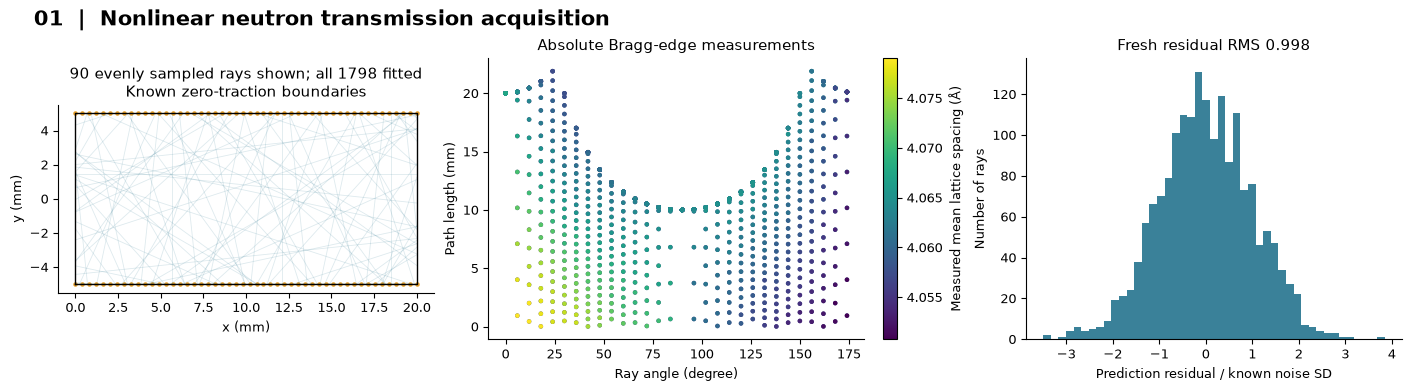

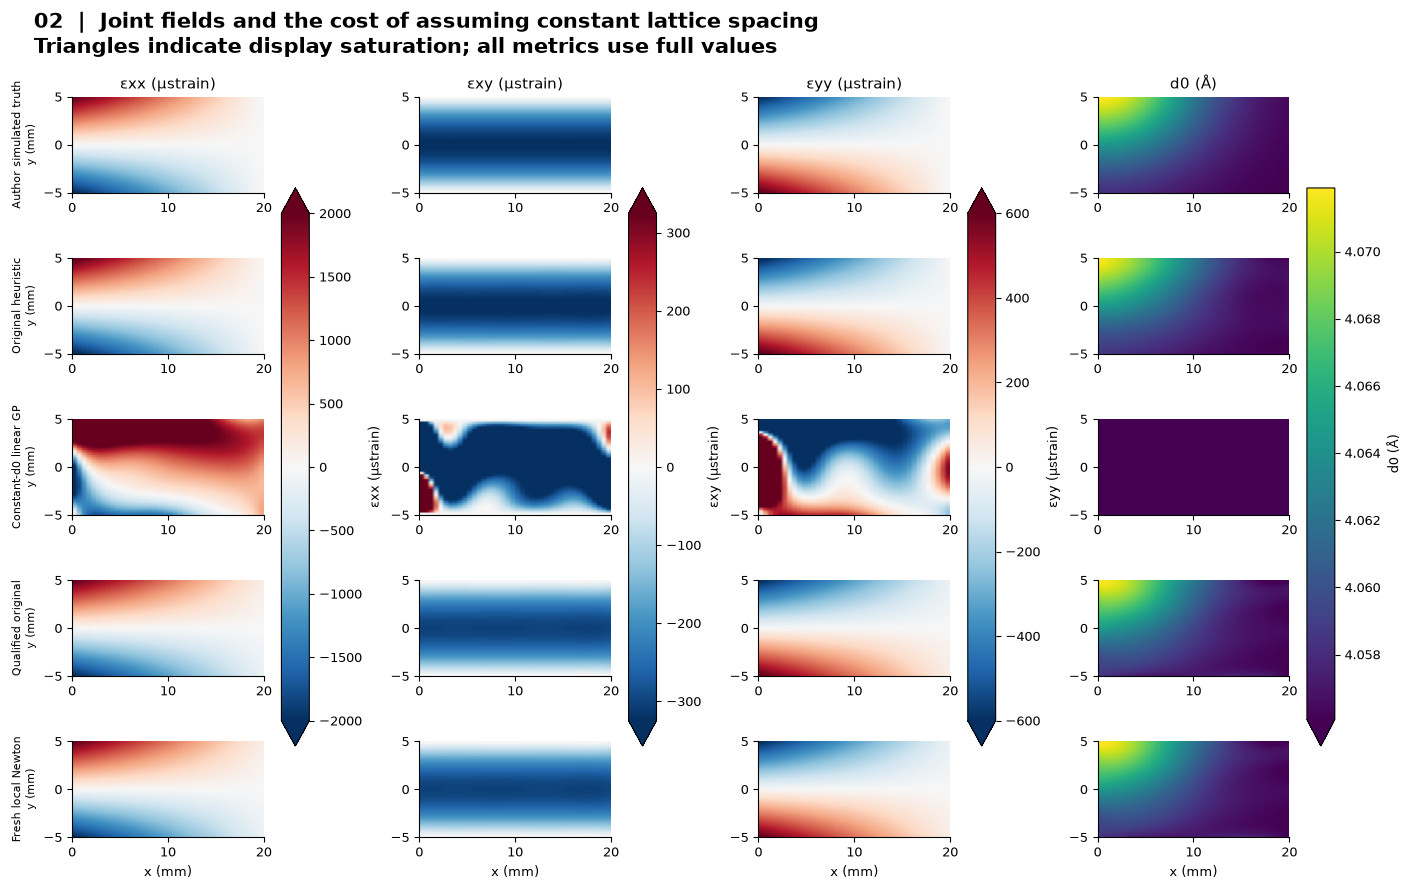

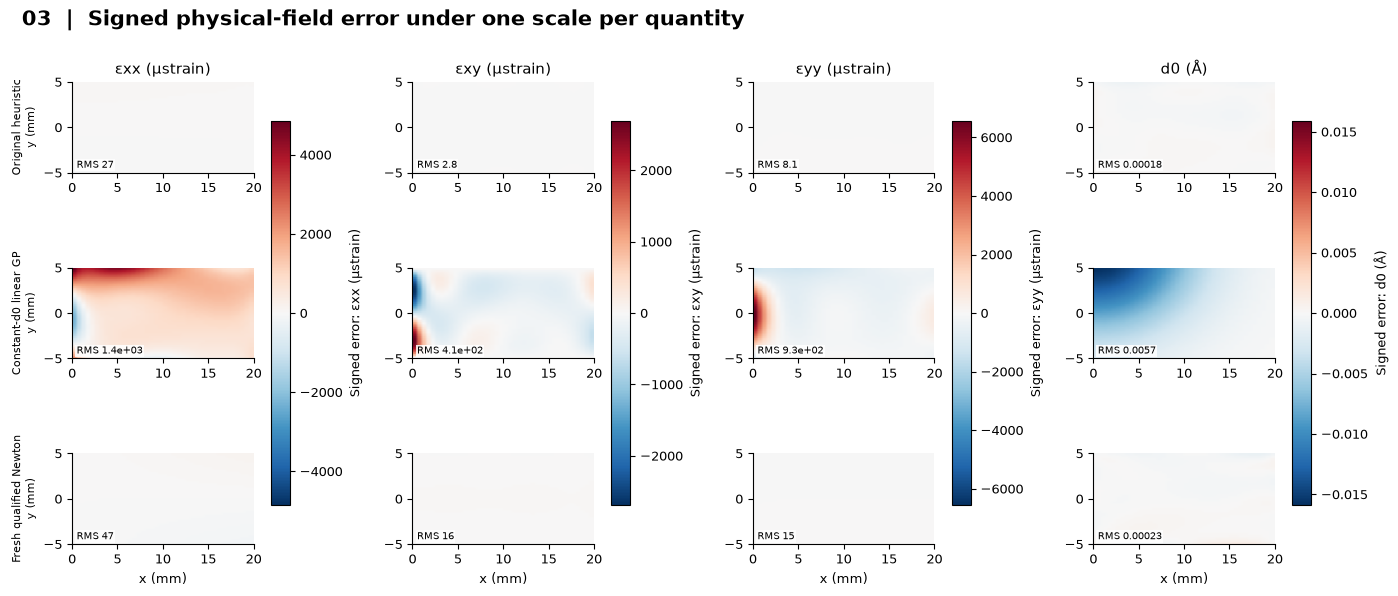

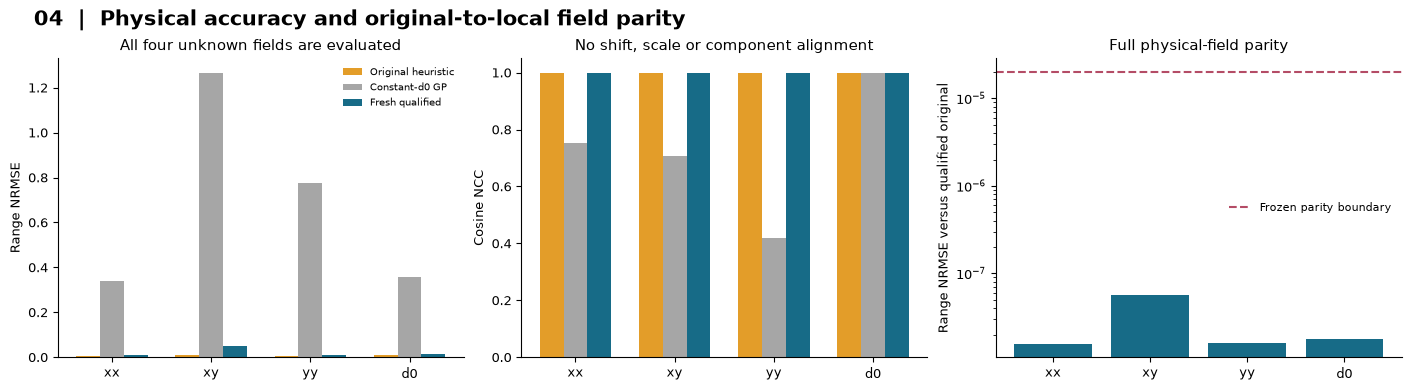

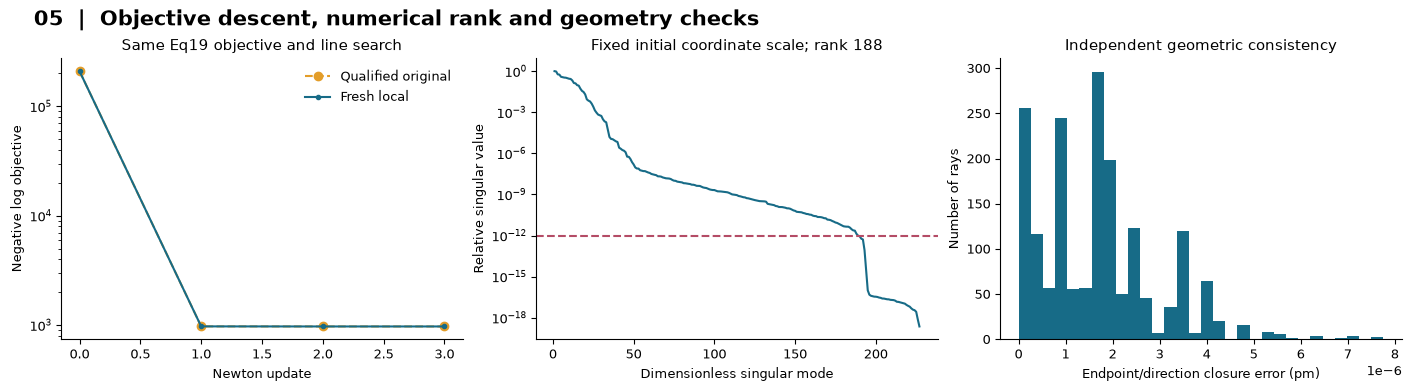

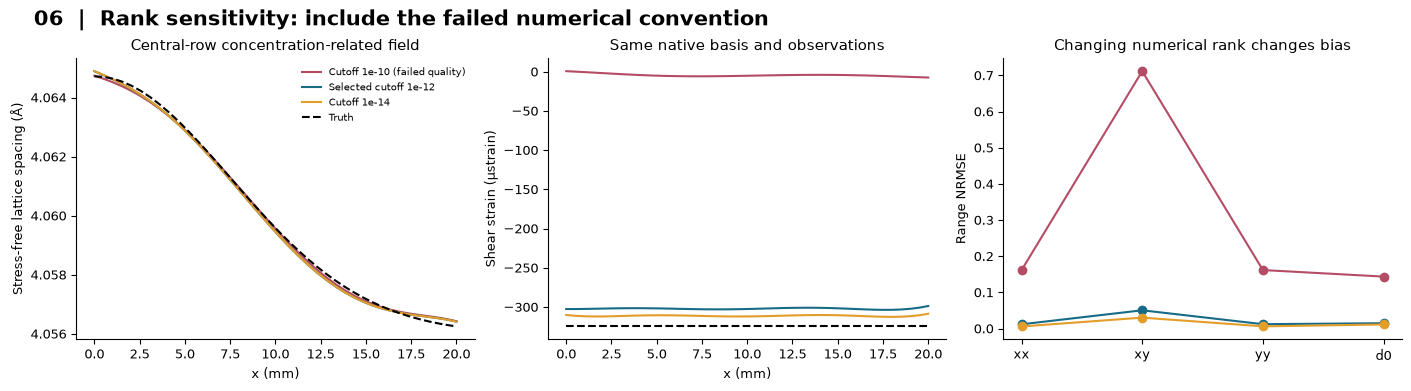

In [4]:
start=time.perf_counter()
cases,histories=sensitivity(data)
print('Two active rank-sensitivity runs seconds:',time.perf_counter()-start)
linear={'strain':original['linear_strain'],'lattice_spacing':np.full_like(truth['lattice_spacing'],4.056)}
groups=[('Reproduced original heuristic',original),('Reproduced constant-d0 GP',linear),('Reproduced qualified original',qualified),('Fresh selected local',fresh),('Fresh cutoff1e-10',cases['10']),('Fresh cutoff1e-14',cases['14'])]
for name,result in groups: print(name,json.dumps(field_metrics(result,truth)))
panels=figures(data,truth,fresh,diagnostics,original,qualified,cases,histories)
export=os.environ.get('IMAGING101_NEUTRON_EXPORT')
if export:
    target=Path(export);target.mkdir(parents=True,exist_ok=True)
    numeric={'fresh_strain':fresh['strain'],'fresh_spacing':fresh['lattice_spacing'],'truth_strain':truth['strain'],'truth_spacing':truth['lattice_spacing'],'original_strain':original['strain'],'original_spacing':original['lattice_spacing'],'linear_strain':original['linear_strain'],'qualified_strain':qualified['strain'],'qualified_spacing':qualified['lattice_spacing'],'history':diagnostics['history'],'prediction':diagnostics['prediction'],'singular_values':diagnostics['first']['singular_values']}
    for key,result in cases.items():
        numeric['cutoff_'+key+'_strain']=result['strain'];numeric['cutoff_'+key+'_spacing']=result['lattice_spacing'];numeric['cutoff_'+key+'_history']=histories[key]
    np.savez_compressed(target.parent/'neutron_experiments.npz',**numeric)
    (target.parent/'neutron_experiments.json').write_text(json.dumps({name:field_metrics(result,truth) for name,result in groups},indent=2),encoding='utf8')
for i,fig in enumerate(panels,1):
    if export:
        for ext in ['png','svg','pdf']:fig.savefig(target/f'neutron-{i}.{ext}',dpi=170)
    display(fig);plt.close(fig)

## 6. Conclusion

Joint estimation separates a nonconstant lattice-spacing field from equilibrium-constrained strain using the full native neutron acquisition. The original-source heuristic, constant-spacing GP, qualified original and fresh local results are clearly distinguished. The selected qualified physical fields agree across implementations well inside the unchanged parity boundary, while coefficient-direction discrepancies in weak modes remain explicitly disclosed.

The numerical sensitivity study rules out interpreting every coordinate/rank convention as an innocent backend choice. A $10^{-10}$ cutoff substantially worsens physical accuracy; both $10^{-12}$ and $10^{-14}$ are useful here, with $10^{-12}$ selected and independently frozen before local adoption. The simulation demonstrates the stated inverse model and known traction condition; it is not evidence of measured-material performance or direct chemical concentration calibration.

In [5]:
residual=(diagnostics['prediction']-data['observations'])/4.056e-4
print('Known-noise-normalized residual RMS:',np.sqrt(np.mean(residual**2)))
print('Largest normalized traction magnitude:',np.max(np.linalg.norm(diagnostics['traction'],axis=1)))
print('Fresh selected objective history:',diagnostics['history'][:,1])
assert len(panels)==6 and np.all(np.diff(diagnostics['history'][:,1])<0)
print('Complete active four-field reconstruction and six computed scientific figures finished.')

Known-noise-normalized residual RMS: 0.9980303579115994
Largest normalized traction magnitude: 4.832995033194325e-06
Fresh selected objective history: [209767.06031397    973.16009328    971.68430816    971.68430816]
Complete active four-field reconstruction and six computed scientific figures finished.
